In [1]:

import os
print("Current folder:", os.getcwd())
print("Files here:", os.listdir())


Current folder: C:\Users\Effendi.Y\OneDrive - amro-asia.org\Documents\mfmod
Files here: ['.gamspy_venv', '.ipynb_checkpoints', 'cge_dyn_hoseoe.ipynb', 'ch12.ipynb', 'Chapter 8.ipynb', 'Chapter 9.ipynb', 'chapter11.ipynb', 'chapter13.ipynb', 'chapter15.ipynb', 'chapter16.ipynb', 'climate1', 'co2_emissions.csv', 'comtrade', 'first_nations_all_fields.csv', 'first_nations_all_fields.geojson', 'first_nations_full.csv', 'first_nations_full.geojson', 'first_nations_location.csv', 'first_nations_raw.json', 'gampsy1.ipynb', 'graph', 'medium.ipynb', 'modelsource', 'panda intro.ipynb', 'plots', 'scenarios basic.ipynb', 'scraper', 'Try1.ipynb', 'Try2.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled10.ipynb', 'Untitled11.ipynb', 'Untitled12.ipynb', 'Untitled13.ipynb', 'Untitled14.ipynb', 'Untitled15.ipynb', 'Untitled16.ipynb', 'Untitled2.ipynb', 'Untitled3.ipynb', 'Untitled4.ipynb', 'Untitled5.ipynb', 'Untitled6.ipynb', 'Untitled7.ipynb', 'Untitled8.ipynb', 'Untitled9.ipynb', 'WorldbankModels

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
%%writefile model.py
# model.py
from __future__ import annotations

import numpy as np
from gamspy import (
    Alias,
    Container,
    Equation,
    Model,
    Ord,
    Parameter,
    Problem,
    Product,
    Sense,
    Set,
    Sum,
    Variable,
)


def build_model():
    """
    Builds and calibrates the DYNCGE model (base year + BAU path containers),
    initializes variables, fixes exogenous variables, and returns a dict of
    model components needed by simulation and results modules.
    """

    m = Container()

    # ===============================================================
    # Definition of sets for suffix ---------------------------------
    # ===============================================================
    u = Set(
        m,
        name="u",
        records=[
            "AGR", "LMN", "HMN", "SRV",
            "CAP", "LAB",
            "HOH", "GOV", "INV", "EXT",
            "IDT", "TRF",
        ],
        description="SAM entry",
    )
    i = Set(m, name="i", domain=u, records=["AGR", "LMN", "HMN", "SRV"], description="goods")
    h = Set(m, name="h", domain=u, records=["CAP", "LAB"], description="factor")
    h_mob = Set(m, name="h_mob", domain=h, records=["LAB"], description="mobile factor")
    t = Set(m, name="t", records=[str(ii) for ii in range(31)], description="time")

    v = Alias(m, name="v", alias_with=u)
    j = Alias(m, name="j", alias_with=i)
    k = Alias(m, name="k", alias_with=h)

    # ===============================================================
    # Data for Dynamics ---------------------------------------------
    # ===============================================================
    ror = Parameter(m, name="ror", description="rate of return of capital")
    dep = Parameter(m, name="dep", description="depreciation rate")
    pop = Parameter(m, name="pop", description="population growth rate")
    zeta = Parameter(m, name="zeta", description="elasticity parameter for investment allocation")

    ror[...] = 0.05
    dep[...] = 0.04
    pop[...] = 0.02
    zeta[...] = 1

    sam_data = np.array(
        [
            [1643.017, 7560.896, 237.841, 1409.202, 0, 0, 3563.257, 0, 919.745, 62.464, 0, 0],
            [1485.854, 10803.527, 15330.764, 18597.270, 0, 0, 32220.169, 329.469, 802.026, 1196.525, 0, 0],
            [1071.954, 4277.721, 113390.269, 48734.424, 0, 0, 27648.678, 4.931, 34979.803, 55083.516, 0, 0],
            [2002.380, 11406.260, 50513.476, 177675.714, 0, 0, 234243.865, 90707.177, 79169.426, 17426.156, 0, 0],
            [5082.506, 7042.697, 21058.821, 163045.396, 0, 0, 0, 0, 0, 0, 0, 0],
            [1435.010, 8942.365, 42510.123, 222732.700, 0, 0, 0, 0, 0, 0, 0, 0],
            [0, 0, 0, 0, 196229.420, 275620.198, 0, 0, 0, 0, 0, 0],
            [0, 0, 0, 0, 0, 0, 52243.041, 0, 0, 0, 34024.445, 4774.091],
            [0, 0, 0, 0, 0, 0, 121930.608, 0, 0, -6059.608, 0, 0],
            [2092.569, 23796.669, 30982.559, 10837.256, 0, 0, 0, 0, 0, 0, 0, 0],
            [433.854, 4068.616, 9418.058, 20103.917, 0, 0, 0, 0, 0, 0, 0, 0],
            [149.278, 2866.853, 1749.385, 8.575, 0, 0, 0, 0, 0, 0, 0, 0],
        ]
    )

    # ===============================================================
    # SAM Data
    # ===============================================================
    SAM = Parameter(
        m,
        name="SAM",
        domain=[u, v],
        records=sam_data,
        description="social accounting matrix for 2005 [bil. JPY]",
    )

    SAMGAP = Parameter(m, name="SAMGAP", domain=u, description="gaps between row sums and column sums")
    SAMGAP[u] = Sum(v, SAM[u, v] - SAM[v, u])

    # ===============================================================
    # Loading the initial values ------------------------------------
    # ===============================================================
    # Base year values
    Y00 = Parameter(m, name="Y00", domain=j, description="composite factor")
    F00 = Parameter(m, name="F00", domain=[h, j], description="factor input")
    X00 = Parameter(m, name="X00", domain=[i, j], description="intermediate input")
    Z00 = Parameter(m, name="Z00", domain=j, description="gross output")
    Xp00 = Parameter(m, name="Xp00", domain=i, description="household consumption")
    Xg00 = Parameter(m, name="Xg00", domain=i, description="government consumption")
    Xv00 = Parameter(m, name="Xv00", domain=i, description="investment demand")
    E00 = Parameter(m, name="E00", domain=i, description="exports")
    M00 = Parameter(m, name="M00", domain=i, description="imports")
    Q00 = Parameter(m, name="Q00", domain=i, description="Armington's composite good")
    D00 = Parameter(m, name="D00", domain=i, description="domestic good")
    Sp00 = Parameter(m, name="Sp00", description="private savings")
    Td00 = Parameter(m, name="Td00", description="direct tax")
    Tz00 = Parameter(m, name="Tz00", domain=j, description="production tax")
    Tm00 = Parameter(m, name="Tm00", domain=j, description="import tariff")
    III00 = Parameter(m, name="III00", description="composite investment")
    II00 = Parameter(m, name="II00", domain=j, description="sectoral investment")
    KK00 = Parameter(m, name="KK00", domain=j, description="capital stock")
    CC00 = Parameter(m, name="CC00", description="composite consumption or felicity")
    FF00 = Parameter(m, name="FF00", domain=h, description="factor endowment")
    Sf00 = Parameter(m, name="Sf00", description="foreign savings in US dollars")
    tauz00 = Parameter(m, name="tauz00", domain=i, description="production tax rate")
    taum00 = Parameter(m, name="taum00", domain=i, description="import tariff rate")

    # Base run value (BAU)
    Y0 = Parameter(m, name="Y0", domain=[j, t], description="composite factor")
    F0 = Parameter(m, name="F0", domain=[h, j, t], description="factor input")
    X0 = Parameter(m, name="X0", domain=[i, j, t], description="intermediate input")
    Z0 = Parameter(m, name="Z0", domain=[j, t], description="gross output")
    Xp0 = Parameter(m, name="Xp0", domain=[i, t], description="household consumption")
    Xv0 = Parameter(m, name="Xv0", domain=[i, t], description="investment demand")
    E0 = Parameter(m, name="E0", domain=[i, t], description="exports")
    M0 = Parameter(m, name="M0", domain=[i, t], description="imports")
    Q0 = Parameter(m, name="Q0", domain=[i, t], description="Armington composite good")
    D0 = Parameter(m, name="D0", domain=[i, t], description="domestic good")
    Sp0 = Parameter(m, name="Sp0", domain=t, description="private savings")
    Td0 = Parameter(m, name="Td0", domain=t, description="direct tax")
    Tz0 = Parameter(m, name="Tz0", domain=[j, t], description="production tax")
    Tm0 = Parameter(m, name="Tm0", domain=[j, t], description="import tariff")
    III0 = Parameter(m, name="III0", domain=t, description="composite investment")
    II0 = Parameter(m, name="II0", domain=[j, t], description="sectoral investment")
    KK0 = Parameter(m, name="KK0", domain=[j, t], description="capital stock")
    CC0 = Parameter(m, name="CC0", domain=t, description="utility BAU")
    FF0 = Parameter(m, name="FF0", domain=[h, t], description="factor endowment")

    pf0 = Parameter(m, name="pf0", domain=[h, j, t], description="factor price")
    py0 = Parameter(m, name="py0", domain=[j, t], description="composite factor price")
    pz0 = Parameter(m, name="pz0", domain=[j, t], description="gross output price")
    pq0 = Parameter(m, name="pq0", domain=[i, t], description="Armington composite good price")
    pe0 = Parameter(m, name="pe0", domain=[i, t], description="export price")
    pm0 = Parameter(m, name="pm0", domain=[i, t], description="import price")
    pd0 = Parameter(m, name="pd0", domain=[i, t], description="domestic good price")
    pk0 = Parameter(m, name="pk0", domain=t, description="investment goods price")
    epsilon0 = Parameter(m, name="epsilon0", domain=t, description="exchange rate")
    PRICE0 = Parameter(m, name="PRICE0", domain=t, description="numeraire")

    # Exogenous variables (paths / constants)
    Xg0 = Parameter(m, name="Xg0", domain=[i, t], description="government consumption")
    Sf0 = Parameter(m, name="Sf0", domain=t, description="foreign savings (USD)")
    pWe = Parameter(m, name="pWe", domain=i, description="world export price (USD)")
    pWm = Parameter(m, name="pWm", domain=i, description="world import price (USD)")
    tauz = Parameter(m, name="tauz", domain=i, description="production tax rate")
    taum = Parameter(m, name="taum", domain=i, description="import tariff rate")

    # ===============================================================
    # Result containers (Scenario) ----------------------------------
    # ===============================================================
    Y1 = Parameter(m, name="Y1", domain=[j, t], description="composite factor")
    F1 = Parameter(m, name="F1", domain=[h, j, t], description="factor input")
    X1 = Parameter(m, name="X1", domain=[i, j, t], description="intermediate input")
    Z1 = Parameter(m, name="Z1", domain=[j, t], description="gross output")
    Xp1 = Parameter(m, name="Xp1", domain=[i, t], description="household consumption")
    Xv1 = Parameter(m, name="Xv1", domain=[i, t], description="investment demand")
    E1 = Parameter(m, name="E1", domain=[i, t], description="exports")
    M1 = Parameter(m, name="M1", domain=[i, t], description="imports")
    Q1 = Parameter(m, name="Q1", domain=[i, t], description="Armington composite good")
    D1 = Parameter(m, name="D1", domain=[i, t], description="domestic good")
    Sp1 = Parameter(m, name="Sp1", domain=t, description="private saving")
    Td1 = Parameter(m, name="Td1", domain=t, description="direct tax")
    Tz1 = Parameter(m, name="Tz1", domain=[j, t], description="production tax")
    Tm1 = Parameter(m, name="Tm1", domain=[i, t], description="import tariff")
    FF1 = Parameter(m, name="FF1", domain=[h, t], description="factor uses")
    II1 = Parameter(m, name="II1", domain=[j, t], description="sectoral investment")
    III1 = Parameter(m, name="III1", domain=t, description="composite investment")
    KK1 = Parameter(m, name="KK1", domain=[j, t], description="capital stock")
    CC1 = Parameter(m, name="CC1", domain=t, description="utility")
    tauz1 = Parameter(m, name="tauz1", domain=[i, t], description="production tax rates")
    taum1 = Parameter(m, name="taum1", domain=[i, t], description="import tariff rates")
    pf1 = Parameter(m, name="pf1", domain=[h, j, t], description="factor price")
    py1 = Parameter(m, name="py1", domain=[j, t], description="composite factor price")
    pz1 = Parameter(m, name="pz1", domain=[j, t], description="gross output price")

    # IMPORTANT FIX: goods prices should be indexed by i, not j
    pd1 = Parameter(m, name="pd1", domain=[i, t], description="domestic good price")
    pm1 = Parameter(m, name="pm1", domain=[i, t], description="import price")
    pe1 = Parameter(m, name="pe1", domain=[i, t], description="export price")
    pq1 = Parameter(m, name="pq1", domain=[i, t], description="Armington composite good price")

    epsilon1 = Parameter(m, name="epsilon1", domain=t, description="exchange rate")
    pk1 = Parameter(m, name="pk1", domain=t, description="capital good price")
    PRICE1 = Parameter(m, name="PRICE1", domain=t, description="numeraire")

    # ===============================================================
    # Base-year construction from SAM
    # ===============================================================
    Td00[...] = SAM["GOV", "HOH"]
    Tz00[j] = SAM["IDT", j]
    Tm00[j] = SAM["TRF", j]
    F00[h, j] = SAM[h, j]
    Y00[j] = Sum(h, F00[h, j])
    X00[i, j] = SAM[i, j]
    Z00[j] = Y00[j] + Sum(i, X00[i, j])
    M00[i] = SAM["EXT", i]
    tauz00[j] = Tz00[j] / Z00[j]
    taum00[j] = Tm00[j] / M00[j]
    Xp00[i] = SAM[i, "HOH"]
    CC00[...] = Sum(i, Xp00[i])
    FF00[h] = SAM["HOH", h]
    E00[i] = SAM[i, "EXT"]
    D00[i] = (1 + tauz00[i]) * Z00[i] - E00[i]
    Q00[i] = (1 + taum00[i]) * M00[i] + D00[i]
    Sf00[...] = SAM["INV", "EXT"]

    # ===============================================================
    # Adjust investment for assumed BAU path
    # ===============================================================
    III_ASS = Parameter(m, name="III_ASS", description="required investment for assumed growth")
    III_SAM = Parameter(m, name="III_SAM", description="observed investment in SAM")
    adj = Parameter(m, name="adj", description="III_ASS vs III_SAM")

    III_ASS[...] = (pop +  dep) / ror * FF00["CAP"]
    III_SAM[...] = Sum(i, SAM[i, "INV"])
    adj[...] = III_ASS / III_SAM

    Xv00[i] = SAM[i, "INV"] * adj
    Xg00[i] = SAM[i, "GOV"] - (Xv00[i] - SAM[i, "INV"])
    Td00[...] = Sum(i, Xg00[i]) - Sum(i, Tz00[i] + Tm00[i])
    Sp00[...] = Sum(h, FF00[h]) - (Sum(i, Xp00[i]) + Td00)

    III00[...] = Sum(i, Xv00[i])
    II00[j] = (Sp00 + Sf00) * F00["CAP", j] / Sum(i, F00["CAP", i])
    KK00[j] = F00["CAP", j] / ror

    # ===============================================================
    # Compute BAU path
    # ===============================================================
    Y0[j, t] = Y00[j] * (1 + pop) ** (Ord(t) - 1)
    F0[h, j, t] = F00[h, j] * (1 + pop) ** (Ord(t) - 1)
    X0[i, j, t] = X00[i, j] * (1 + pop) ** (Ord(t) - 1)
    Z0[j, t] = Z00[j] * (1 + pop) ** (Ord(t) - 1)
    Xp0[i, t] = Xp00[i] * (1 + pop) ** (Ord(t) - 1)
    Xv0[i, t] = Xv00[i] * (1 + pop) ** (Ord(t) - 1)
    E0[i, t] = E00[i] * (1 + pop) ** (Ord(t) - 1)
    M0[i, t] = M00[i] * (1 + pop) ** (Ord(t) - 1)
    Q0[i, t] = Q00[i] * (1 + pop) ** (Ord(t) - 1)
    D0[i, t] = D00[i] * (1 + pop) ** (Ord(t) - 1)
    FF0[h, t] = FF00[h] * (1 + pop) ** (Ord(t) - 1)
    III0[t] = III00 * (1 + pop) ** (Ord(t) - 1)
    II0[j, t] = II00[j] * (1 + pop) ** (Ord(t) - 1)
    KK0[j, t] = KK00[j] * (1 + pop) ** (Ord(t) - 1)
    CC0[t] = CC00 * (1 + pop) ** (Ord(t) - 1)
    Sp0[t] = Sp00 * (1 + pop) ** (Ord(t) - 1)
    Td0[t] = Td00 * (1 + pop) ** (Ord(t) - 1)
    Tz0[j, t] = Tz00[j] * (1 + pop) ** (Ord(t) - 1)
    Tm0[i, t] = Tm00[i] * (1 + pop) ** (Ord(t) - 1)

    pf0[h, j, t] = 1
    py0[j, t] = 1
    pz0[j, t] = 1
    pq0[i, t] = 1
    pe0[i, t] = 1
    pm0[i, t] = 1
    pd0[i, t] = 1
    pk0[t] = 1
    epsilon0[t] = 1
    PRICE0[t] = 1

    Xg0[i, t] = Xg00[i] * (1 + pop) ** (Ord(t) - 1)
    Sf0[t] = Sf00 * (1 + pop) ** (Ord(t) - 1)
    pWe[i] = 1
    pWm[i] = 1
    tauz[i] = tauz00[i]
    taum[i] = taum00[i]

    # ===============================================================
    # Calibration
    # ===============================================================
    sigma = Parameter(m, name="sigma", domain=i, description="elasticity of substitution")
    psi = Parameter(m, name="psi", domain=i, description="elasticity of transformation")
    eta = Parameter(m, name="eta", domain=i, description="substitution elasticity parameter")
    phi = Parameter(m, name="phi", domain=i, description="transformation elasticity parameter")

    sigma[i] = 2
    psi[i] = 2
    eta[i] = (sigma[i] - 1) / sigma[i]
    phi[i] = (psi[i] + 1) / psi[i]

    alpha = Parameter(m, name="alpha", domain=i, description="consumption shares")
    a = Parameter(m, name="a", description="scale in consumption")
    beta = Parameter(m, name="beta", domain=[h, j], description="value-added shares")
    b = Parameter(m, name="b", domain=j, description="scale in production")
    ax = Parameter(m, name="ax", domain=[i, j], description="IO coefficients")
    ay = Parameter(m, name="ay", domain=j, description="VA coefficient")
    lamda = Parameter(m, name="lamda", domain=i, description="investment shares")
    iota = Parameter(m, name="iota", description="scale in investment")
    deltam = Parameter(m, name="deltam", domain=i, description="Armington share M")
    deltad = Parameter(m, name="deltad", domain=i, description="Armington share D")
    gamma = Parameter(m, name="gamma", domain=i, description="Armington scale")
    xid = Parameter(m, name="xid", domain=i, description="CET share D")
    xie = Parameter(m, name="xie", domain=i, description="CET share E")
    theta = Parameter(m, name="theta", domain=i, description="CET scale")
    ssp = Parameter(m, name="ssp", description="propensity to save")

    alpha[i] = Xp00[i] / Sum(j, Xp00[j])
    a[...] = CC00 / Product(j, Xp00[j] ** alpha[j])
    beta[h, j] = F00[h, j] / Sum(k, F00[k, j])
    b[j] = Y00[j] / Product(h, F00[h, j] ** beta[h, j])
    ax[i, j] = X00[i, j] / Z00[j]
    ay[j] = Y00[j] / Z00[j]
    lamda[i] = Xv00[i] / Sum(j, Xv00[j])
    iota[...] = III00 / Product(i, Xv00[i] ** lamda[i])

    deltam[i] = (
        (1 + taum00[i]) * M00[i] ** (1 - eta[i])
        / ((1 + taum00[i]) * M00[i] ** (1 - eta[i]) + D00[i] ** (1 - eta[i]))
    )
    deltad[i] = D00[i] ** (1 - eta[i]) / (
        (1 + taum00[i]) * M00[i] ** (1 - eta[i]) + D00[i] ** (1 - eta[i])
    )
    gamma[i] = Q00[i] / (
        deltam[i] * M00[i] ** eta[i] + deltad[i] * D00[i] ** eta[i]
    ) ** (1 / eta[i])

    xie[i] = E00[i] ** (1 - phi[i]) / (E00[i] ** (1 - phi[i]) + D00[i] ** (1 - phi[i]))
    xid[i] = D00[i] ** (1 - phi[i]) / (E00[i] ** (1 - phi[i]) + D00[i] ** (1 - phi[i]))
    theta[i] = Z00[i] / (xie[i] * E00[i] ** phi[i] + xid[i] * D00[i] ** phi[i]) ** (1 / phi[i])

    ssp[...] = Sp00 / (Sum([h, j], F00[h, j]) - Td00)

    # ===============================================================
    # Variables
    # ===============================================================
    Y = Variable(m, name="Y", type="free", domain=j, description="composite factor")
    F = Variable(m, name="F", type="free", domain=[h, j], description="factor input")
    X = Variable(m, name="X", type="free", domain=[i, j], description="intermediate input")
    Z = Variable(m, name="Z", type="free", domain=j, description="gross output")
    Xp = Variable(m, name="Xp", type="free", domain=i, description="household consumption")
    Xg = Variable(m, name="Xg", type="free", domain=i, description="government consumption")
    Xv = Variable(m, name="Xv", type="free", domain=i, description="investment demand")
    E = Variable(m, name="E", type="free", domain=i, description="exports")
    M = Variable(m, name="M", type="free", domain=i, description="imports")
    Q = Variable(m, name="Q", type="free", domain=i, description="Armington good")
    D = Variable(m, name="D", type="free", domain=i, description="domestic good")
    FF = Variable(m, name="FF", type="free", domain=h, description="factor endowments")
    pf = Variable(m, name="pf", type="free", domain=[h, j], description="factor price")
    py = Variable(m, name="py", type="free", domain=j, description="VA price")
    pz = Variable(m, name="pz", type="free", domain=j, description="output price")
    pq = Variable(m, name="pq", type="free", domain=i, description="Armington price")
    pe = Variable(m, name="pe", type="free", domain=i, description="export price")
    pm = Variable(m, name="pm", type="free", domain=i, description="import price")
    pd = Variable(m, name="pd", type="free", domain=i, description="domestic price")
    pk = Variable(m, name="pk", type="free", description="investment price")
    epsilon = Variable(m, name="epsilon", type="free", description="exchange rate")
    Sp = Variable(m, name="Sp", type="free", description="private savings")
    Sf = Variable(m, name="Sf", type="free", description="foreign savings")
    Td = Variable(m, name="Td", type="free", description="direct tax")
    Tz = Variable(m, name="Tz", type="free", domain=j, description="production tax")
    Tm = Variable(m, name="Tm", type="free", domain=i, description="import tariff")
    KK = Variable(m, name="KK", type="free", domain=j, description="capital stock")
    II = Variable(m, name="II", type="free", domain=j, description="sectoral investment")
    III = Variable(m, name="III", type="free", description="composite investment")
    PRICE = Variable(m, name="PRICE", type="free", description="numeraire")

    # ===============================================================
    # Equations
    # ===============================================================
    eqpy = Equation(m, name="eqpy", domain=j)
    eqF = Equation(m, name="eqF", domain=[h, j])
    eqX = Equation(m, name="eqX", domain=[i, j])
    eqY = Equation(m, name="eqY", domain=j)
    eqpzs = Equation(m, name="eqpzs", domain=j)

    eqTd = Equation(m, name="eqTd")
    eqTz = Equation(m, name="eqTz", domain=j)
    eqTm = Equation(m, name="eqTm", domain=i)

    eqXv = Equation(m, name="eqXv", domain=i)
    eqSp = Equation(m, name="eqSp")
    eqXp = Equation(m, name="eqXp", domain=i)

    eqpe = Equation(m, name="eqpe", domain=i)
    eqpm = Equation(m, name="eqpm", domain=i)
    eqepsilon = Equation(m, name="eqepsilon")

    eqpqs = Equation(m, name="eqpqs", domain=i)
    eqM = Equation(m, name="eqM", domain=i)
    eqD = Equation(m, name="eqD", domain=i)

    eqpzd = Equation(m, name="eqpzd", domain=i)
    eqE = Equation(m, name="eqE", domain=i)
    eqDs = Equation(m, name="eqDs", domain=i)

    eqpqd = Equation(m, name="eqpqd", domain=i)

    eqpf1 = Equation(m, name="eqpf1", domain=[h_mob])
    eqpf2 = Equation(m, name="eqpf2", domain=[h_mob, i, j])
    eqpf3 = Equation(m, name="eqpf3", domain=j)

    eqpk = Equation(m, name="eqpk")
    eqIII = Equation(m, name="eqIII")
    eqII = Equation(m, name="eqII", domain=j)
    eqPRICE = Equation(m, name="eqPRICE")

    # ===============================================================
    # Model equations
    # ===============================================================
    eqpy[j] = Y[j] == b[j] * Product(h, F[h, j] ** beta[h, j])
    eqF[h, j] = F[h, j] == beta[h, j] * py[j] * Y[j] / pf[h, j]
    eqX[i, j] = X[i, j] == ax[i, j] * Z[j]
    eqY[j] = Y[j] == ay[j] * Z[j]
    eqpzs[j] = pz[j] == ay[j] * py[j] + Sum(i, ax[i, j] * pq[i])

    eqTd[...] = Td == Sum(i, pq[i] * Xg[i]) - Sum(i, Tm[i] + Tz[i])
    eqTz[j] = Tz[j] == tauz[j] * pz[j] * Z[j]
    eqTm[i] = Tm[i] == taum[i] * pm[i] * M[i]

    eqXv[i] = Xv[i] == lamda[i] * pk * Sum(j, II[j]) / pq[i]
    eqSp[...] = Sp == ssp * (Sum([h, j], pf[h, j] * F[h, j]) - Td)
    eqXp[i] = Xp[i] == alpha[i] * (Sum([h, j], pf[h, j] * F[h, j]) - Sp - Td) / pq[i]

    eqpe[i] = pe[i] == epsilon * pWe[i]
    eqpm[i] = pm[i] == epsilon * pWm[i]
    eqepsilon[...] = Sum(i, pWe[i] * E[i]) + Sf == Sum(i, pWm[i] * M[i])

    eqpqs[i] = Q[i] == gamma[i] * (
        deltam[i] * M[i] ** eta[i] + deltad[i] * D[i] ** eta[i]
    ) ** (1 / eta[i])

    eqM[i] = (
        M[i]
        == (gamma[i] ** eta[i] * deltam[i] * pq[i] / ((1 + taum[i]) * pm[i]))
        ** (1 / (1 - eta[i]))
        * Q[i]
    )
    eqD[i] = (
        D[i]
        == (gamma[i] ** eta[i] * deltad[i] * pq[i] / pd[i])
        ** (1 / (1 - eta[i]))
        * Q[i]
    )

    eqpzd[i] = Z[i] == theta[i] * (
        xie[i] * E[i] ** phi[i] + xid[i] * D[i] ** phi[i]
    ) ** (1 / phi[i])

    eqE[i] = (
        E[i]
        == (theta[i] ** phi[i] * xie[i] * (1 + tauz[i]) * pz[i] / pe[i])
        ** (1 / (1 - phi[i]))
        * Z[i]
    )
    eqDs[i] = (
        D[i]
        == (theta[i] ** phi[i] * xid[i] * (1 + tauz[i]) * pz[i] / pd[i])
        ** (1 / (1 - phi[i]))
        * Z[i]
    )

    eqpqd[i] = Q[i] == Xp[i] + Xg[i] + Xv[i] + Sum(j, X[i, j])

    eqpf1[h_mob] = Sum(j, F[h_mob, j]) == FF[h_mob]
    eqpf2[h_mob, i, j] = pf[h_mob, j] == pf[h_mob, i]  # as in your original
    eqpf3[j] = F["CAP", j] == ror * KK[j]

    eqpk[...] = Sum(j, II[j]) == III
    eqIII[...] = iota * Product(i, Xv[i] ** lamda[i]) == III

    eqII[j] = pk * II[j] == pf["CAP", j] ** zeta * F["CAP", j] / Sum(
        i, pf["CAP", i] ** zeta * F["CAP", i]
    ) * (Sp + epsilon * Sf)

    CC = a * Product(i, Xp[i] ** alpha[i])

    # NOTE: This uses pq[j] but j is an alias for goods; kept as in original
    eqPRICE[...] = Sum(j, pq[j] * Q00[j] / Sum(i, Q00[i])) == PRICE

    # ===============================================================
    # Initialize variables
    # ===============================================================
    Y.l[j] = Y00[j]
    F.l[h, j] = F00[h, j]
    X.l[i, j] = X00[i, j]
    Z.l[j] = Z00[j]
    Xp.l[i] = Xp00[i]
    Xv.l[i] = Xv00[i]
    E.l[i] = E00[i]
    M.l[i] = M00[i]
    Q.l[i] = Q00[i]
    D.l[i] = D00[i]

    pf.l[h, j] = 1
    py.l[j] = 1
    pz.l[j] = 1
    pq.l[i] = 1
    pe.l[i] = 1
    pm.l[i] = 1
    pd.l[i] = 1
    pk.l = 1
    epsilon.l = 1

    Sp.l = Sp00
    Td.l = Td00
    Tz.l[j] = Tz00[j]
    Tm.l[i] = Tm00[i]
    FF.l[h] = FF00[h]
    III.l = III00
    II.l[j] = II00[j]

    PRICE.fx = 1

    # Fix exogenous / state variables (initially)
    FF.fx[h_mob] = FF00[h_mob]
    KK.fx[j] = KK00[j]
    Xg.fx[i] = Xg00[i]
    Sf.fx = Sf00

    # ===============================================================
    # Define model object
    # ===============================================================
    dyncge = Model(
        m,
        name="dyncge",
        equations=m.getEquations(),
        problem=Problem.NLP,
        sense=Sense.MAX,
        objective=CC,
    )

    # Solve baseline once (as in your script)
    dyncge.solve()

    return {
        # core handles
        "m": m,
        "dyncge": dyncge,

        # sets/aliases
        "u": u, "v": v, "i": i, "j": j, "h": h, "k": k, "h_mob": h_mob, "t": t,

        # dynamics scalars
        "ror": ror, "dep": dep, "pop": pop, "zeta": zeta,

        # policy parameters / exogenous paths
        "tauz": tauz, "taum": taum, "Xg0": Xg0, "Sf0": Sf0,

        # base-year and BAU containers used later
        "Q00": Q00,
        "Y0": Y0, "F0": F0, "X0": X0, "Z0": Z0, "Xp0": Xp0, "Xv0": Xv0,
        "E0": E0, "M0": M0, "Q0": Q0, "D0": D0,
        "Sp0": Sp0, "Td0": Td0, "Tz0": Tz0, "Tm0": Tm0,
        "III0": III0, "II0": II0, "KK0": KK0, "CC0": CC0, "FF0": FF0,
        "pz0": pz0, "pd0": pd0, "pm0": pm0, "pe0": pe0, "pq0": pq0,
        "pf0": pf0, "py0": py0, "epsilon0": epsilon0, "pk0": pk0,

        # scenario result containers
        "Y1": Y1, "F1": F1, "X1": X1, "Z1": Z1, "Xp1": Xp1, "Xv1": Xv1,
        "E1": E1, "M1": M1, "Q1": Q1, "D1": D1,
        "Sp1": Sp1, "Td1": Td1, "Tz1": Tz1, "Tm1": Tm1,
        "FF1": FF1, "II1": II1, "III1": III1, "KK1": KK1, "CC1": CC1,
        "tauz1": tauz1, "taum1": taum1,
        "pf1": pf1, "py1": py1, "pz1": pz1,
        "pd1": pd1, "pm1": pm1, "pe1": pe1, "pq1": pq1,
        "epsilon1": epsilon1, "pk1": pk1, "PRICE1": PRICE1,

        # variables needed for simulation loop and storing
        "Y": Y, "F": F, "X": X, "Z": Z, "Xp": Xp, "Xg": Xg, "Xv": Xv,
        "E": E, "M": M, "Q": Q, "D": D,
        "FF": FF, "KK": KK, "II": II, "III": III,
        "pf": pf, "py": py, "pz": pz, "pd": pd, "pm": pm, "pe": pe, "pq": pq,
        "epsilon": epsilon, "pk": pk, "PRICE": PRICE,
        "Sp": Sp, "Td": Td, "Tz": Tz, "Tm": Tm, "Sf": Sf,
    }

Writing model.py


In [5]:
%%writefile simulation.py
# simulation.py
from __future__ import annotations


def run_simulation(ctx: dict):
    """
    Runs the recursive-dynamic simulation: abolish import tariffs (taum = 0),
    solve each period, store results, and update state variables (FF, KK).
    """
    m = ctx["m"]
    dyncge = ctx["dyncge"]

    i = ctx["i"]
    j = ctx["j"]
    h = ctx["h"]
    t = ctx["t"]
    h_mob = ctx["h_mob"]

    pop = ctx["pop"]
    dep = ctx["dep"]

    taum = ctx["taum"]
    Xg0 = ctx["Xg0"]
    Sf0 = ctx["Sf0"]

    # variables
    Y = ctx["Y"]; F = ctx["F"]; X = ctx["X"]; Z = ctx["Z"]
    Xp = ctx["Xp"]; Xv = ctx["Xv"]; E = ctx["E"]; Mv = ctx["M"]
    Q = ctx["Q"]; D = ctx["D"]
    Sp = ctx["Sp"]; Td = ctx["Td"]; Tz = ctx["Tz"]; Tm = ctx["Tm"]
    FF = ctx["FF"]; II = ctx["II"]; III = ctx["III"]; KK = ctx["KK"]
    pf = ctx["pf"]; py = ctx["py"]; pz = ctx["pz"]
    pd = ctx["pd"]; pe = ctx["pe"]; pm = ctx["pm"]; pq = ctx["pq"]
    pk = ctx["pk"]; epsilon = ctx["epsilon"]; PRICE = ctx["PRICE"]
    tauz = ctx["tauz"]; Sf = ctx["Sf"]; Xg = ctx["Xg"]

    # result containers
    Y1 = ctx["Y1"]; F1 = ctx["F1"]; X1 = ctx["X1"]; Z1 = ctx["Z1"]
    Xp1 = ctx["Xp1"]; Xv1 = ctx["Xv1"]; E1 = ctx["E1"]; M1 = ctx["M1"]
    Q1 = ctx["Q1"]; D1 = ctx["D1"]
    Sp1 = ctx["Sp1"]; Td1 = ctx["Td1"]; Tz1 = ctx["Tz1"]; Tm1 = ctx["Tm1"]
    FF1 = ctx["FF1"]; II1 = ctx["II1"]; III1 = ctx["III1"]; KK1 = ctx["KK1"]
    CC1 = ctx["CC1"]

    tauz1 = ctx["tauz1"]; taum1 = ctx["taum1"]
    pf1 = ctx["pf1"]; py1 = ctx["py1"]; pz1 = ctx["pz1"]
    pd1 = ctx["pd1"]; pe1 = ctx["pe1"]; pm1 = ctx["pm1"]; pq1 = ctx["pq1"]
    pk1 = ctx["pk1"]; epsilon1 = ctx["epsilon1"]; PRICE1 = ctx["PRICE1"]

    # ===============================================================
    # Policy shock: abolish import tariffs
    # ===============================================================
    taum[i] = 0

    # ===============================================================
    # Recursive dynamic loop
    # ===============================================================
    for iteration, _ in t.records.itertuples(index=False):
        dyncge.solve()

        # Store results for this period
        Y1[j, iteration] = Y.l[j]
        F1[h, j, iteration] = F.l[h, j]
        X1[i, j, iteration] = X.l[i, j]
        Z1[j, iteration] = Z.l[j]
        Xp1[i, iteration] = Xp.l[i]
        Xv1[i, iteration] = Xv.l[i]
        E1[i, iteration] = E.l[i]
        M1[i, iteration] = Mv.l[i]
        Q1[i, iteration] = Q.l[i]
        D1[i, iteration] = D.l[i]
        Sp1[iteration] = Sp.l
        Td1[iteration] = Td.l
        Tz1[j, iteration] = Tz.l[j]
        Tm1[i, iteration] = Tm.l[i]
        FF1[h, iteration] = FF.l[h]
        II1[j, iteration] = II.l[j]
        III1[iteration] = III.l
        KK1[j, iteration] = KK.l[j]
        CC1[iteration] = dyncge.objective_value

        tauz1[i, iteration] = tauz[i]
        taum1[i, iteration] = taum[i]
        pf1[h, j, iteration] = pf.l[h, j]
        py1[j, iteration] = py.l[j]
        pz1[j, iteration] = pz.l[j]

        # IMPORTANT FIX: store goods prices with index i (not j)
        pd1[i, iteration] = pd.l[i]
        pe1[i, iteration] = pe.l[i]
        pm1[i, iteration] = pm.l[i]
        pq1[i, iteration] = pq.l[i]

        pk1[iteration] = pk.l
        epsilon1[iteration] = epsilon.l
        PRICE1[iteration] = PRICE.l

        # Update state variables
        FF.fx[h_mob] = FF.l[h_mob] * (1 + pop)
        KK.fx[j] = (1 - dep) * KK.l[j] + II.l[j]

        # Update exogenous paths for next period
        if int(iteration) < 30:
            Xg.fx[i] = Xg0[i, str(int(iteration) + 1)]
            Sf.fx = Sf0[str(int(iteration) + 1)]

    return ctx

Writing simulation.py


In [6]:
%%writefile results.py
# --- paste the full results.py code here ---
# results.py
from __future__ import annotations

import math
import matplotlib.pyplot as plt
from pathlib import Path
from gamspy import Ord, Parameter, Product, Sum

from model import build_model
from simulation import run_simulation


def tidy_time(df, tcol="t"):
    out = df.copy()
    out[tcol] = out[tcol].astype(int)
    return out.sort_values(tcol)


def compute_results(ctx: dict):
    """
    Post-process: compute deviations vs BAU, welfare (EV), print tables, and plot.
    """

    m = ctx["m"]
    dyncge = ctx["dyncge"]

    i = ctx["i"]; j = ctx["j"]; h = ctx["h"]; t = ctx["t"]
    ror = ctx["ror"]

    # Baseline/BAU
    Y0 = ctx["Y0"]; F0 = ctx["F0"]; X0 = ctx["X0"]; Z0 = ctx["Z0"]
    Xp0 = ctx["Xp0"]; Xv0 = ctx["Xv0"]; E0 = ctx["E0"]; M0 = ctx["M0"]
    Q0 = ctx["Q0"]; D0 = ctx["D0"]
    Sp0 = ctx["Sp0"]; Td0 = ctx["Td0"]; Tz0 = ctx["Tz0"]; Tm0 = ctx["Tm0"]
    III0 = ctx["III0"]; II0 = ctx["II0"]; KK0 = ctx["KK0"]; CC0 = ctx["CC0"]; FF0 = ctx["FF0"]
    pz0 = ctx["pz0"]; pd0 = ctx["pd0"]; pm0 = ctx["pm0"]; pe0 = ctx["pe0"]; pq0 = ctx["pq0"]
    pf0 = ctx["pf0"]; py0 = ctx["py0"]; epsilon0 = ctx["epsilon0"]; pk0 = ctx["pk0"]

    # Scenario
    Y1 = ctx["Y1"]; F1 = ctx["F1"]; X1 = ctx["X1"]; Z1 = ctx["Z1"]
    Xp1 = ctx["Xp1"]; Xv1 = ctx["Xv1"]; E1 = ctx["E1"]; M1 = ctx["M1"]
    Q1 = ctx["Q1"]; D1 = ctx["D1"]
    Sp1 = ctx["Sp1"]; Td1 = ctx["Td1"]; Tz1 = ctx["Tz1"]; Tm1 = ctx["Tm1"]
    III1 = ctx["III1"]; II1 = ctx["II1"]; KK1 = ctx["KK1"]; CC1 = ctx["CC1"]; FF1 = ctx["FF1"]
    pz1 = ctx["pz1"]; pd1 = ctx["pd1"]; pm1 = ctx["pm1"]; pe1 = ctx["pe1"]; pq1 = ctx["pq1"]
    pf1 = ctx["pf1"]; py1 = ctx["py1"]; epsilon1 = ctx["epsilon1"]; pk1 = ctx["pk1"]

    # Consumption parameters for EV
    # (a, alpha were created in model scope; fetch via container symbol table)
    alpha = m["alpha"]
    a = m["a"]

    # ===============================================================
    # Aftermath Computation
    # ===============================================================
    assert math.isclose(dyncge.objective_value, 539570.5027, rel_tol=0.001)

    # Changes (%)
    dY = Parameter(m, name="dY", domain=[j, t])
    dF = Parameter(m, name="dF", domain=[h, j, t])
    dX = Parameter(m, name="dX", domain=[i, j, t])
    dZ = Parameter(m, name="dZ", domain=[j, t])
    dXp = Parameter(m, name="dXp", domain=[i, t])
    dXv = Parameter(m, name="dXv", domain=[i, t])
    dE = Parameter(m, name="dE", domain=[i, t])
    dM = Parameter(m, name="dM", domain=[i, t])
    dQ = Parameter(m, name="dQ", domain=[i, t])
    dD = Parameter(m, name="dD", domain=[i, t])
    dSp = Parameter(m, name="dSp", domain=t)
    dTd = Parameter(m, name="dTd", domain=t)
    dTz = Parameter(m, name="dTz", domain=[j, t])
    dTm = Parameter(m, name="dTm", domain=[i, t])
    dFF = Parameter(m, name="dFF", domain=[h, t])
    dKK = Parameter(m, name="dKK", domain=[j, t])
    dII = Parameter(m, name="dII", domain=[j, t])
    dIII = Parameter(m, name="dIII", domain=t)
    dCC = Parameter(m, name="dCC", domain=t)

    dpz = Parameter(m, name="dpz", domain=[j, t])

    # IMPORTANT FIX: goods price changes should be indexed by i (not j)
    dpd = Parameter(m, name="dpd", domain=[i, t])
    dpm = Parameter(m, name="dpm", domain=[i, t])
    dpe = Parameter(m, name="dpe", domain=[i, t])
    dpq = Parameter(m, name="dpq", domain=[i, t])

    dpf = Parameter(m, name="dpf", domain=[h, j, t])
    dpy = Parameter(m, name="dpy", domain=[j, t])
    depsilon = Parameter(m, name="depsilon", domain=t)
    dpk = Parameter(m, name="dpk", domain=t)

    # Compute deviations
    dY[j, t].where[Y0[j, t]] = (Y1[j, t] / Y0[j, t] - 1) * 100
    dF[h, j, t].where[F0[h, j, t]] = (F1[h, j, t] / F0[h, j, t] - 1) * 100
    dX[i, j, t].where[X0[i, j, t]] = (X1[i, j, t] / X0[i, j, t] - 1) * 100
    dZ[j, t].where[Z0[j, t]] = (Z1[j, t] / Z0[j, t] - 1) * 100
    dXp[i, t].where[Xp0[i, t]] = (Xp1[i, t] / Xp0[i, t] - 1) * 100
    dXv[i, t].where[Xv0[i, t]] = (Xv1[i, t] / Xv0[i, t] - 1) * 100
    dE[i, t].where[E0[i, t]] = (E1[i, t] / E0[i, t] - 1) * 100
    dM[i, t].where[M0[i, t]] = (M1[i, t] / M0[i, t] - 1) * 100
    dQ[i, t].where[Q0[i, t]] = (Q1[i, t] / Q0[i, t] - 1) * 100
    dD[i, t].where[D0[i, t]] = (D1[i, t] / D0[i, t] - 1) * 100
    dSp[t].where[Sp0[t]] = (Sp1[t] / Sp0[t] - 1) * 100
    dTd[t].where[Td0[t]] = (Td1[t] / Td0[t] - 1) * 100
    dTz[j, t].where[Tz0[j, t]] = (Tz1[j, t] / Tz0[j, t] - 1) * 100
    dTm[i, t].where[Tm0[i, t]] = (Tm1[i, t] / Tm0[i, t] - 1) * 100
    dFF[h, t].where[FF0[h, t]] = (FF1[h, t] / FF0[h, t] - 1) * 100
    dII[j, t].where[II0[j, t]] = (II1[j, t] / II0[j, t] - 1) * 100
    dIII[t].where[III0[t]] = (III1[t] / III0[t] - 1) * 100
    dKK[j, t].where[KK0[j, t]] = (KK1[j, t] / KK0[j, t] - 1) * 100
    dCC[t].where[CC0[t]] = (CC1[t] / CC0[t] - 1) * 100

    dpz[j, t].where[pz0[j, t]] = (pz1[j, t] / pz0[j, t] - 1) * 100

    dpd[i, t].where[pd0[i, t]] = (pd1[i, t] / pd0[i, t] - 1) * 100
    dpm[i, t].where[pm0[i, t]] = (pm1[i, t] / pm0[i, t] - 1) * 100
    dpe[i, t].where[pe0[i, t]] = (pe1[i, t] / pe0[i, t] - 1) * 100
    dpq[i, t].where[pq0[i, t]] = (pq1[i, t] / pq0[i, t] - 1) * 100

    dpf[h, j, t].where[pf0[h, j, t]] = (pf1[h, j, t] / pf0[h, j, t] - 1) * 100
    dpy[j, t].where[py0[j, t]] = (py1[j, t] / py0[j, t] - 1) * 100
    depsilon[t].where[epsilon0[t]] = (epsilon1[t] / epsilon0[t] - 1) * 100
    dpk[t].where[pk0[t]] = (pk1[t] / pk0[t] - 1) * 100

    # Welfare measure: Hicksian EV
    EV = Parameter(m, name="EV", domain=t, description="equivalent variations [current]")
    EV_TTL = Parameter(m, name="EV_TTL", description="total EV [discounted Sum]")

    EV[t] = (CC1[t] - CC0[t]) / a / Product(i, (alpha[i] / 1) ** alpha[i])
    EV_TTL[...] = Sum(t, EV[t] / (1 + ror) ** (Ord(t) - 1))

    print("EV_TTL: ", round(EV_TTL.records.value[0], 3))

    # ===============================================================
    # Print main results
    # ===============================================================
    print("=" * 80)
    print("MAIN RESULTS: Abolition of Import Tariffs Simulation")
    print("=" * 80)

    print("\n1. WELFARE ANALYSIS")
    print("-" * 40)
    print(f"Total Equivalent Variation (discounted): {EV_TTL.records.value[0]:,.2f}")

    print("\nEquivalent Variation by Period (first 10 periods):")
    ev_records = EV.records.head(10)
    for _, row in ev_records.iterrows():
        print(f"  Period {row['t']}: {row['value']:,.2f}")

    print("\n2. UTILITY (FELICITY) CHANGES [%]")
    print("-" * 40)
    cc_changes = dCC.records.head(10)
    for _, row in cc_changes.iterrows():
        print(f"  Period {row['t']}: {row['value']:.3f}%")

    print("\n3. SELECTED MACRO INDICATORS - Period 30 Changes [%]")
    print("-" * 40)
    period_30 = dCC.records[dCC.records["t"] == "30"]
    if not period_30.empty:
        print(f"  Utility Change: {period_30['value'].values[0]:.3f}%")

    print("\n4. TRADE BALANCE - Period 0 and 30")
    print("-" * 40)
    for period in ["0", "30"]:
        exports = E1.records[E1.records["t"] == period]["value"].sum()
        imports = M1.records[M1.records["t"] == period]["value"].sum()
        print(f"  Period {period}:")
        print(f"    Total Exports: {exports:,.2f}")
        print(f"    Total Imports: {imports:,.2f}")
        print(f"    Trade Balance: {exports - imports:,.2f}")

    print("\n5. SECTORAL OUTPUT CHANGES - Period 30 [%]")
    print("-" * 40)
    output_30 = dZ.records[dZ.records["t"] == "30"]
    for _, row in output_30.iterrows():
        print(f"  {row['j']}: {row['value']:.3f}%")

    print("\n6. PRICE CHANGES - Period 30 [%]")
    print("-" * 40)
    print("  Composite Good Prices:")
    pq_30 = dpq.records[dpq.records["t"] == "30"]
    for _, row in pq_30.iterrows():
        print(f"    {row['i']}: {row['value']:.3f}%")

    exrate_30 = depsilon.records[depsilon.records["t"] == "30"]
    if not exrate_30.empty:
        print(f"  Exchange Rate: {exrate_30['value'].values[0]:.3f}%")

    print("\n7. CAPITAL STOCK CHANGES - Period 30 [%]")
    print("-" * 40)
    kk_30 = dKK.records[dKK.records["t"] == "30"]
    for _, row in kk_30.iterrows():
        print(f"  {row['j']}: {row['value']:.3f}%")

    print("\n" + "=" * 80)

    # ===============================================================
    # Plotting
    # ===============================================================
    outdir = Path("plots")
    outdir.mkdir(exist_ok=True)

    # Plot utility change (dCC)
    df_cc = tidy_time(dCC.records)
    plt.figure(figsize=(8, 4))
    plt.plot(df_cc["t"], df_cc["value"], marker="o")
    plt.axhline(0, color="black", linewidth=1)
    plt.title("Utility Change vs BAU (dCC, %)")
    plt.xlabel("Period (t)")
    plt.ylabel("Change (%)")
    plt.tight_layout()
    plt.savefig(outdir / "dCC_utility_change.png", dpi=200)
    plt.show()

    # Optional: plot EV
    df_ev = tidy_time(EV.records)
    plt.figure(figsize=(8, 4))
    plt.plot(df_ev["t"], df_ev["value"], marker="o", color="tab:green")
    plt.axhline(0, color="black", linewidth=1)
    plt.title("Equivalent Variation (EV) by Period")
    plt.xlabel("Period (t)")
    plt.ylabel("EV (level)")
    plt.tight_layout()
    plt.savefig(outdir / "EV_by_period.png", dpi=200)
    plt.show()

    # Optional: plot sectoral output changes (dZ)
    df_dz = dZ.records.copy()
    df_dz["t"] = df_dz["t"].astype(int)
    df_dz = df_dz.sort_values("t")
    dz_wide = df_dz.pivot(index="t", columns="j", values="value")

    plt.figure(figsize=(10, 5))
    for col in dz_wide.columns:
        plt.plot(dz_wide.index, dz_wide[col], label=col)
    plt.axhline(0, color="black", linewidth=1)
    plt.title("Sectoral Output Change vs BAU (dZ, %)")
    plt.xlabel("Period (t)")
    plt.ylabel("Change (%)")
    plt.legend(ncol=2, fontsize=9)
    plt.tight_layout()
    plt.savefig(outdir / "dZ_sector_output_change.png", dpi=200)
    plt.show()

    return {
        "EV": EV,
        "EV_TTL": EV_TTL,
        "dCC": dCC,
        "dZ": dZ,
        "dpq": dpq,
        "depsilon": depsilon,
        "dKK": dKK,
    }


def main():
    ctx = build_model()
    ctx = run_simulation(ctx)
    compute_results(ctx)


if __name__ == "__main__":
    main()

Writing results.py


In [7]:
import os
[f for f in os.listdir() if f.endswith(".py")]

['model.py', 'results.py', 'simulation.py']

EV_TTL:  -0.0
MAIN RESULTS: Abolition of Import Tariffs Simulation

1. WELFARE ANALYSIS
----------------------------------------
Total Equivalent Variation (discounted): -0.00

Equivalent Variation by Period (first 10 periods):
  Period 1: -0.00
  Period 2: 0.00
  Period 3: 0.00
  Period 4: 0.00
  Period 5: 0.00
  Period 6: 0.00
  Period 7: 0.00
  Period 8: -0.00
  Period 9: -0.00
  Period 10: -0.00

2. UTILITY (FELICITY) CHANGES [%]
----------------------------------------
  Period 1: -0.000%
  Period 2: 0.000%
  Period 3: 0.000%
  Period 4: 0.000%
  Period 5: 0.000%
  Period 6: 0.000%
  Period 7: 0.000%
  Period 8: -0.000%
  Period 9: -0.000%
  Period 10: -0.000%

3. SELECTED MACRO INDICATORS - Period 30 Changes [%]
----------------------------------------
  Utility Change: 0.000%

4. TRADE BALANCE - Period 0 and 30
----------------------------------------
  Period 0:
    Total Exports: 73,768.66
    Total Imports: 67,709.05
    Trade Balance: 6,059.61
  Period 30:
    Total Exports:

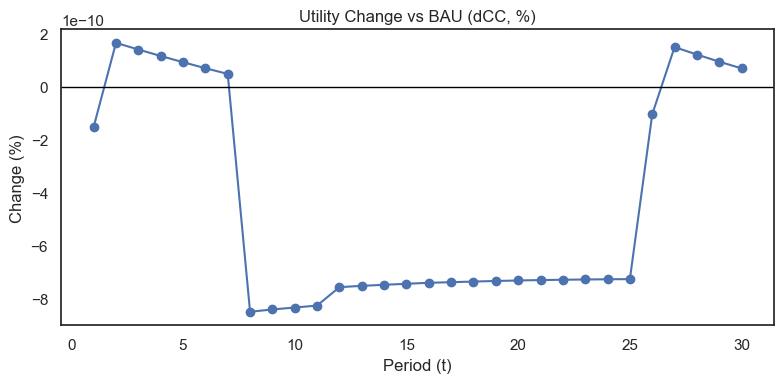

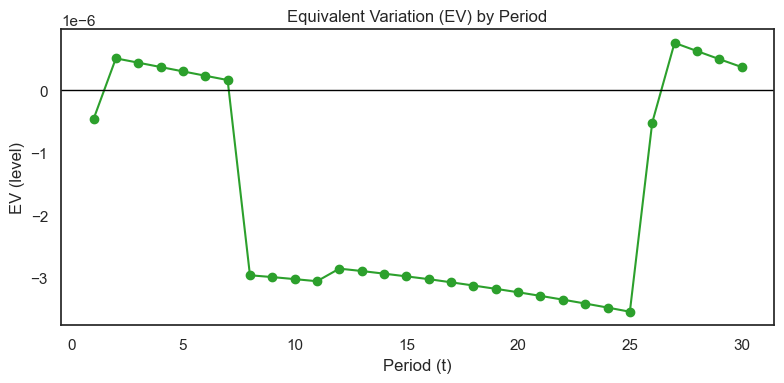

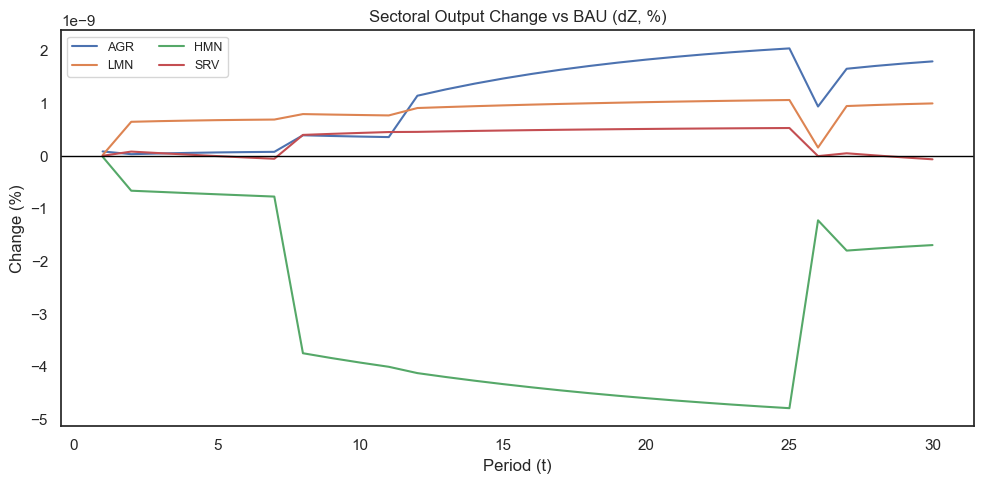

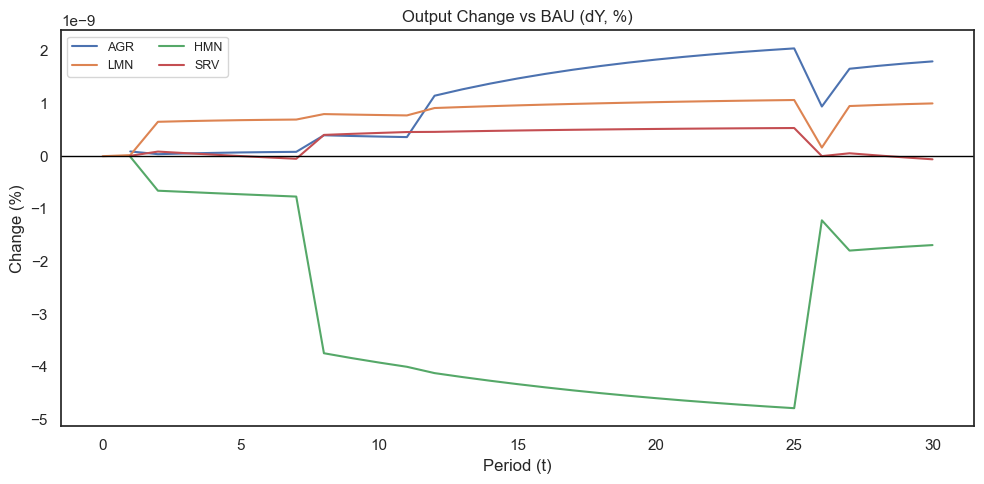

DYNCGE pipeline:   0%|          | 0/3 [00:00<?, ?it/s]

EV_TTL:  5741.294
MAIN RESULTS: Abolition of Import Tariffs Simulation

1. WELFARE ANALYSIS
----------------------------------------
Total Equivalent Variation (discounted): 5,741.29

Equivalent Variation by Period (first 10 periods):
  Period 0: 412.33
  Period 1: 399.72
  Period 2: 388.18
  Period 3: 377.68
  Period 4: 368.18
  Period 5: 359.64
  Period 6: 352.01
  Period 7: 345.28
  Period 8: 339.39
  Period 9: 334.33

2. UTILITY (FELICITY) CHANGES [%]
----------------------------------------
  Period 0: 0.139%
  Period 1: 0.132%
  Period 2: 0.125%
  Period 3: 0.120%
  Period 4: 0.114%
  Period 5: 0.109%
  Period 6: 0.105%
  Period 7: 0.101%
  Period 8: 0.097%
  Period 9: 0.094%

3. SELECTED MACRO INDICATORS - Period 30 Changes [%]
----------------------------------------
  Utility Change: 0.069%

4. TRADE BALANCE - Period 0 and 30
----------------------------------------
  Period 0:
    Total Exports: 78,135.82
    Total Imports: 72,076.22
    Trade Balance: 6,059.61
  Period 30:
 

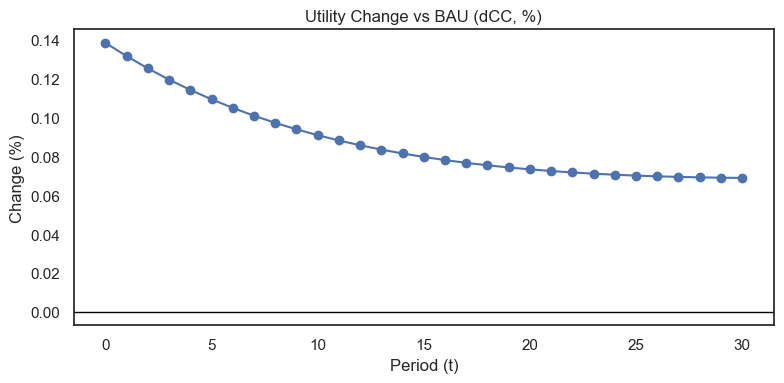

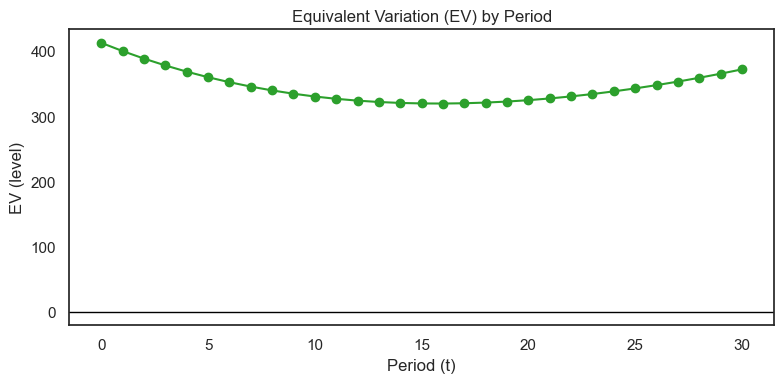

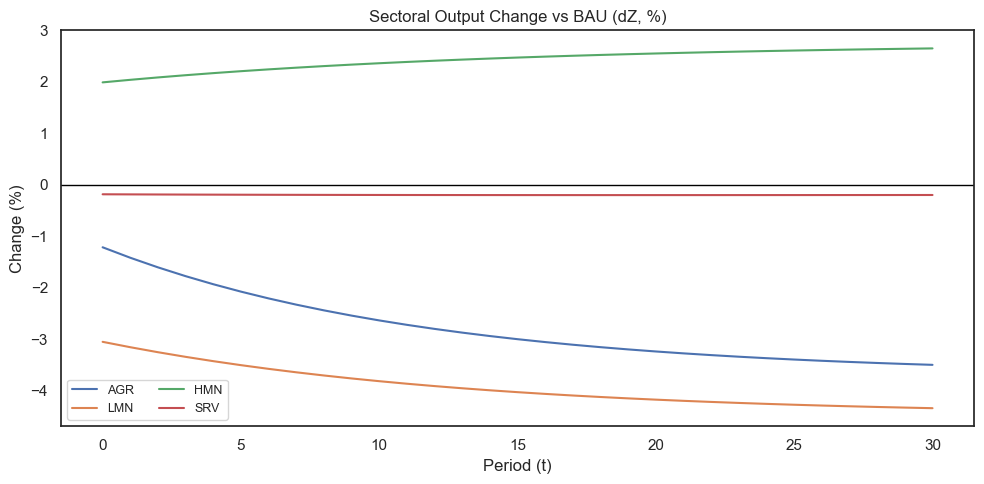

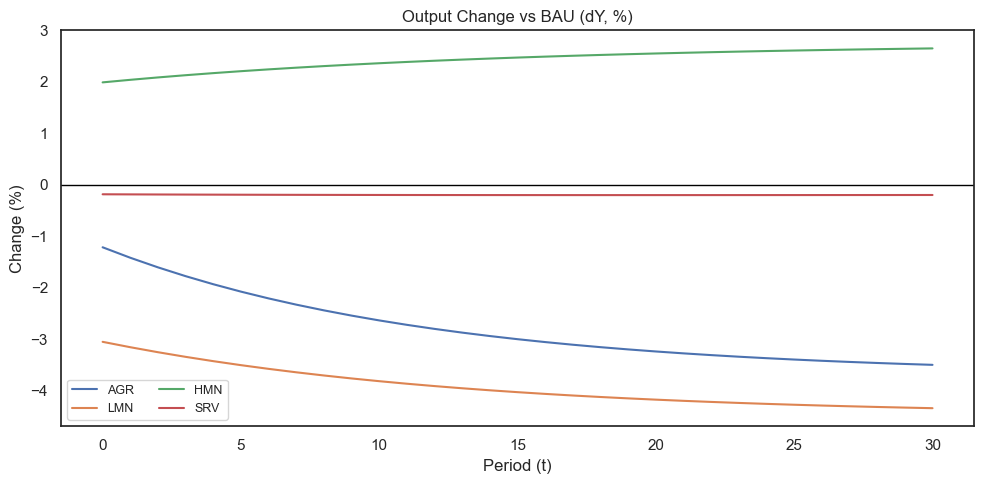

{'EV': Parameter(name='EV', domain=[Set(name='t', domain=['*'])]),
 'EV_TTL': Parameter(name='EV_TTL', domain=[]),
 'dCC': Parameter(name='dCC', domain=[Set(name='t', domain=['*'])]),
 'dZ': Parameter(name='dZ', domain=[Alias(name='j', alias_with=Set(name='i', domain=[Set(name='u', domain=['*'])])), Set(name='t', domain=['*'])]),
 'dY': Parameter(name='dY', domain=[Alias(name='j', alias_with=Set(name='i', domain=[Set(name='u', domain=['*'])])), Set(name='t', domain=['*'])]),
 'dF': Parameter(name='dF', domain=[Set(name='h', domain=[Set(name='u', domain=['*'])]), Alias(name='j', alias_with=Set(name='i', domain=[Set(name='u', domain=['*'])])), Set(name='t', domain=['*'])]),
 'dXp': Parameter(name='dXp', domain=[Set(name='i', domain=[Set(name='u', domain=['*'])]), Set(name='t', domain=['*'])]),
 'dpq': Parameter(name='dpq', domain=[Set(name='i', domain=[Set(name='u', domain=['*'])]), Set(name='t', domain=['*'])]),
 'depsilon': Parameter(name='depsilon', domain=[Set(name='t', domain=['*'])

In [24]:
from results import main
main()

# Generating progress bar
from tqdm.notebook import tqdm

steps = ["Build model + solve base", "Run simulation loop", "Compute results + print + plot"]

with tqdm(total=len(steps), desc="DYNCGE pipeline") as pbar:
    # 1) Build
    from model import build_model
    ctx = build_model()
    pbar.update(1)

    # 2) Simulation
    from simulation import run_simulation
    ctx = run_simulation(ctx)
    pbar.update(1)

    # 3) Results
    from results import compute_results
    out = compute_results(ctx)
    pbar.update(1)

out

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

In [26]:
dZ = out["dZ"]        # a GAMSPy Parameter
df = dZ.records.copy()   # pandas DataFrame with columns: j, t, value

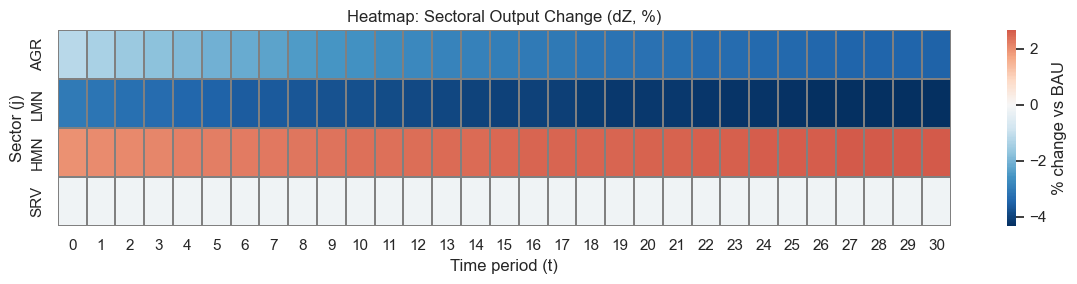

In [27]:
df["t"] = df["t"].astype(int)
heat = df.pivot(index="j", columns="t", values="value").sort_index()

plt.figure(figsize=(12, 3))
sns.heatmap(
    heat,
    cmap="RdBu_r",
    center=0,
    linewidths=0.3,
    linecolor="grey",
    cbar_kws={"label": "% change vs BAU"}
)
plt.title("Heatmap: Sectoral Output Change (dZ, %)")
plt.xlabel("Time period (t)")
plt.ylabel("Sector (j)")
plt.tight_layout()
plt.show()

In [28]:
dF = out.get("dF", None)  # only if you returned it; see note below

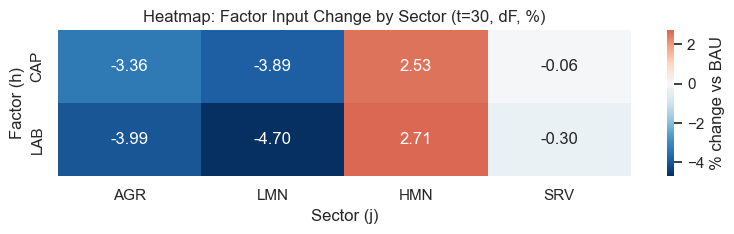

In [29]:
df = dF.records.copy()
df = df[df["t"] == "30"]  # pick period 30
heat = df.pivot(index="h", columns="j", values="value")

plt.figure(figsize=(8, 2.5))
sns.heatmap(
    heat,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "% change vs BAU"}
)
plt.title("Heatmap: Factor Input Change by Sector (t=30, dF, %)")
plt.xlabel("Sector (j)")
plt.ylabel("Factor (h)")
plt.tight_layout()
plt.show()